In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import jax
from jax.typing import ArrayLike
from jax import numpy as jnp # JAX version of NumPy.
from flax import nnx # Neural networks in JAX.
import optax # Optimization in JAX.
import gymnasium as gym
import numpy as np # For compatibility with gymnasium.
from tqdm import tqdm
import pennylane as qml
import json
import yaml
import tyro
from pathlib import Path
import qnrl
import matplotlib.pyplot as plt

jax.config.update("jax_enable_x64", True) # Enable double-precision (default is single-precision).

In [3]:
# Create default configuration storage object.
store = qnrl.store.HashStore()

In [4]:
def inspect_model_pmfs_for_observation(obs, model, atoms):
    """Display the model return-atom density matrix for a given observation."""
    
    # Put single observation into a 1-batch for input to model.
    observations = jnp.array([obs])

    # Generate action PMF for current observation.
    return_pmfs = model(observations)
    return_pmfs = return_pmfs[0] # There's only 1 item in batch.
    
    
    ## Display the observation.
    print(f"{observations = }")
    
    # Compute Q-value for each action.
    for a, rpmf in enumerate(return_pmfs):
        q = jnp.sum(rpmf * atoms)
        print(f"Q(a{a}): {q}")
    
    ### Show a matplotlib figure for PDF render.
    #
    ## Action PMF.
    # fig = plt.figure()
    # ax = fig.add_subplot(111)
    # x = jnp.arange(action_pmf[0].shape[-1])
    # ax.bar(x, action_pmf[0])
    # ax.set_xticks(x, [f"$a_{{{i}}}$" for i in range(len(x))], rotation=90)
    # ax.set_xlabel("Action atom")
    # ax.set_ylabel("Probability")
    # ax.set_title("Action PMF based on return-atom amplitude kickback")
    #
    ## Plot the return PMF for each action individually.
    n_actions, n_returns = return_pmfs.shape
    fig = plt.figure()
    x = jnp.arange(n_returns)
    fig, axs = plt.subplots(n_actions, 1, sharex=True, sharey=True)
    axs = axs.flatten()
    for a in range(n_actions):
        axs[a].bar(jnp.arange(n_returns), return_pmfs[a])
        axs[a].set_xticks(x, [f"$z_{{{i}}}$" for i in range(len(x))], rotation=90)
        axs[a].set_title(f"$a_{{{a}}}$")
        axs[a].set_xlabel("Return atom")
        axs[a].set_ylabel("Probability")
    fig.suptitle("Return-atom PMF for each action $a_i$")
    plt.tight_layout()

def inspect_model_pmfs_for_env(env, model, atoms):
    """Display the model return-atom density matrix for a random environment observation."""
    
    # Generate a batch of environment observations.
    # observations = jnp.array([env.reset()[0] for _ in range(config.batch_size)])
    # 
    obs = env.reset()[0]
    # for _ in range(10): obs = env.step(0)[0] # Mutate the environment to get a different observation.
    # observations = jnp.array([obs for _ in range(config.batch_size)])
    inspect_model_pmfs_for_observation(obs, model, atoms)
    
    return obs

In [5]:
from qnrl.algorithms.c51 import C51
from qnrl.optimizer import *
from qnrl.gym import *
from qnrl.modules import *

import ale_py
gym.register_envs(ale_py)

# # CartPole.
# env = EnvConfig(env_id="CartPole-v1")
# din = 4
# num_actions = 2
# z_min = -100
# z_max = 100

# MountainCar.
env = EnvConfig(env_id="MountainCar-v0")
din = 2
num_actions = 3
z_min = -100
z_max = 100

# # Acrobot-v1
# din = 6
# num_actions = 3
# env = EnvConfig(env_id="Acrobot-v1")
# z_min = -100
# z_max = 100

# # ALE/Asteroids-v5
# din = 128
# num_actions = 14
# env = EnvConfig(env_id="ALE/Asteroids-v5", extra_args=dict(obs_type="ram"))
# z_min = 1
# z_max = 10000

# num_atoms = 101
# num_atoms = 2**7
num_atoms = 2**5

batch_size = 128

# Experiment configuration.
config = C51(
    buffer_size=10_000,
    seed=0,
    batch_size=batch_size,
    total_timesteps=500_000,
    # total_timesteps=50_000,
    # total_timesteps=20_000, # quick test default.
    learning_starts=10_000,
    policy_update_frequency=10,
    target_update_frequency=500,
    gamma=0.99,
    tau=1.0,
    eps_start=1,
    eps_end=5e-2,
    eps_exploration=0.5,
    #
    # env=EnvConfig(env_id="CartPole-v1"),
    # env=EnvConfig(env_id="MountainCar-v0"),
    env=env,
    num_atoms=num_atoms,
    z_min=z_min,
    z_max=z_max,
    model=Sequential(
        layers={
            # 'RescaleInput': RescaleInput(scale=[2.4, 2.5, 0.21, 2.5]),
            'QNetworkLinear': DistQNetworkLinear(
                din=din,
                num_actions=num_actions,
                num_atoms=num_atoms,
                douts=[120, 84],
                # douts=[120,],
                # douts=[60,42], # Does well at 20,000 epochs.
                # douts=[30,21], # Does not solve at 20,000 epochs.
                # douts=[30,],
                # douts=[60,],
                rngs_kwargs=dict(default=42),
            ),
        },
    ),
    # optimizer=Adam(learning_rate=2.5e-4),
    # optimizer=Adam(learning_rate=2.5e-3),
    # optimizer=Adam(learning_rate=1e-3, eps=0.01/batch_size),
    optimizer=Adam(learning_rate=1e-3),
)

if store.exists(config):
    print(f"Already exists in store")
    cfg_hash, cfg_str = store.hash(config)
else:
    print(f"New hash")
    # Generate hash for the current config and store it for later retrieval.
    cfg_hash, cfg_str = store.store_obj(config)

print(f"Config String: {cfg_str}")
print(f"Config Hash: {cfg_hash}")

New hash
Config String: {"type": "c51", "env": {"env_id": "MountainCar-v0", "render_mode": null, "max_episode_steps": null, "extra_args": null}, "metric_manager": null, "checkpoint": null, "model": {"type": "Sequential", "layers": {"QNetworkLinear": {"type": "DistQNetworkLinear", "din": 2, "num_actions": 3, "num_atoms": 32, "douts": [120, 84], "rngs_kwargs": {"default": 42}}}, "key_order": ["QNetworkLinear"]}, "optimizer": {"type": "adam", "learning_rate": 0.001, "b1": 0.9, "b2": 0.999, "eps": 1e-08, "eps_root": 0.0, "mu_dtype": null, "nesterov": false}, "num_atoms": 32, "z_min": -100, "z_max": 100, "buffer_size": 10000, "seed": 0, "batch_size": 128, "total_timesteps": 500000, "learning_starts": 10000, "policy_update_frequency": 10, "target_update_frequency": 500, "gamma": 0.99, "tau": 1.0, "eps_start": 1, "eps_end": 0.05, "eps_exploration": 0.5}
Config Hash: 87dc8a9c-4238-5de9-a005-c781914ad3e3


In [6]:
qnrl.tools.get_model_total_parameter_count(config.model)

18684

observations = Array([[-0.43094933,  0.        ]], dtype=float32)
Q(a0): -0.28155931541997736
Q(a1): -0.20938218841630762
Q(a2): 0.7093785570994449


<Figure size 640x480 with 0 Axes>

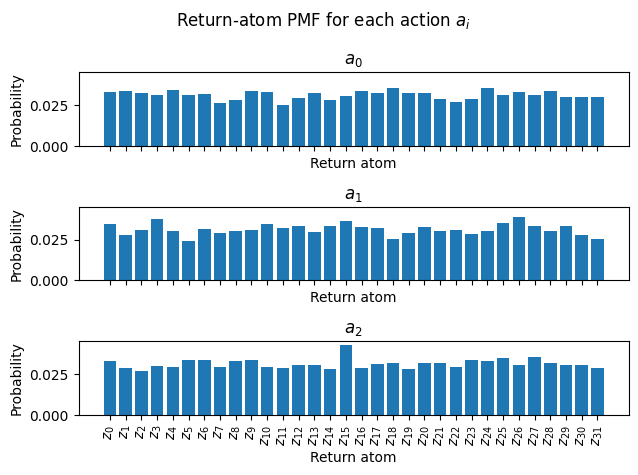

In [7]:
# Inspect density matrices before training.
# Preserve the observation that was used to compare inspect after training.
atoms = jnp.linspace(start=config.z_min, stop=config.z_max, num=config.num_atoms)
obs_inspect = inspect_model_pmfs_for_env(config.env.make(), config.model, atoms)

In [8]:
train = True
save_metrics = True
metric_filepath = Path(f"./metrics/{cfg_hash}.json")

In [9]:
if metric_filepath.exists() and not train:
    print(f"Loading existing train results")
    print(f"Store: {store.path}")
    print(f"Hash: {cfg_hash}")
    print(f"History: {metric_filepath}")
    history_list = qnrl.tools.load_train_results(metric_filepath)
    history_dict = qnrl.tools.listofdict_to_dictoflist(history_list)
else:
    print(f"Training")
    print(f"Store: {store.path}")
    print(f"Hash: {cfg_hash}")
    print(f"History: {metric_filepath}")
    
    history_list = config.train()
    history_dict = qnrl.tools.listofdict_to_dictoflist(history_list)
    
    # Preserve training results.
    if save_metrics:
        qnrl.tools.save_train_results(metric_filepath, history_list)

Training
Store: hashstore.json
Hash: 87dc8a9c-4238-5de9-a005-c781914ad3e3
History: metrics/87dc8a9c-4238-5de9-a005-c781914ad3e3.json


  2%|▏         | 9995/500000 [00:08<06:50, 1192.44step/s, episode_step=9847, episode_reward=-200, episode_length=200, episode_time=0.166]/Users/derieux/research/qnrl/.venv/lib/python3.12/site-packages/jax/_src/ops/scatter.py:108: FutureWarning: scatter inputs have incompatible types: cannot safely cast value from dtype=float64 to dtype=float32 with jax_numpy_dtype_promotion='standard'. In future JAX releases this will result in an error.
  warnings.warn(
100%|██████████| 500000/500000 [10:56<00:00, 761.24step/s, episode_step=5e+5, episode_reward=-190, episode_length=190, episode_time=0.268, loss_step=5e+5, loss=2.550911]      


Text(0, 0.5, 'episode_reward')

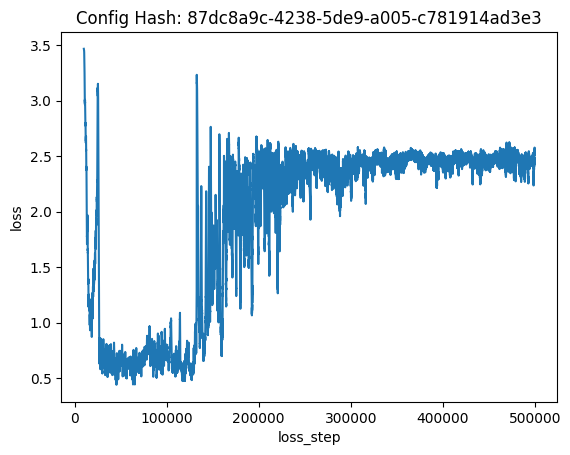

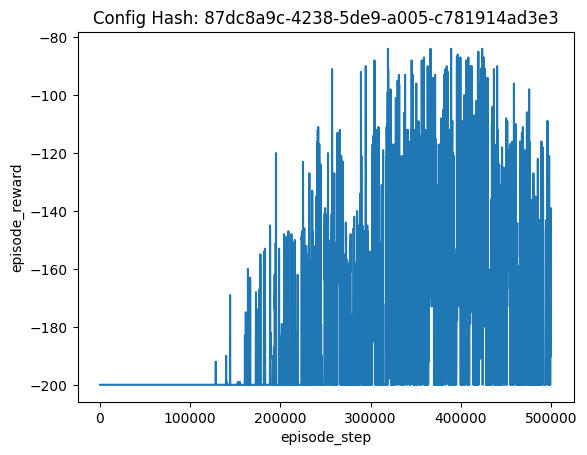

In [10]:
import matplotlib.pyplot as plt

history_dict = qnrl.tools.listofdict_to_dictoflist(qnrl.tools.load_train_results(metric_filepath))

plt.figure()
plt.title(f"Config Hash: {cfg_hash}")
plt.plot(history_dict['loss_step'], history_dict['loss'])
plt.xlabel('loss_step')
plt.ylabel('loss')

plt.figure()
plt.title(f"Config Hash: {cfg_hash}")
plt.plot(history_dict['episode_step'], history_dict['episode_reward'])
plt.xlabel('episode_step')
plt.ylabel('episode_reward')

./figures/87dc8a9c-4238-5de9-a005-c781914ad3e3.pdf


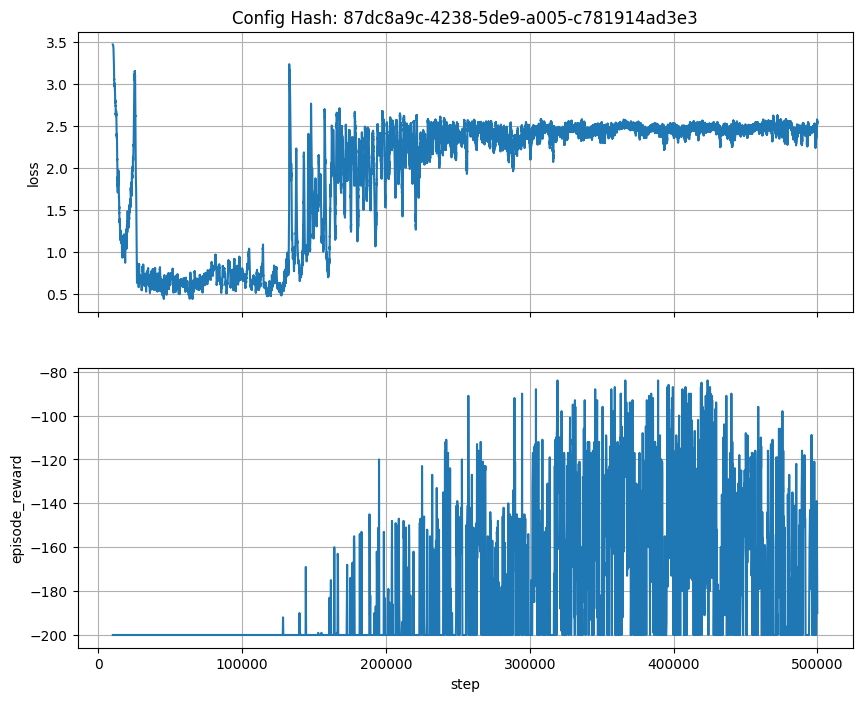

In [11]:
# Plot loss and episode reward on the same plot.

history_dict = qnrl.tools.listofdict_to_dictoflist(qnrl.tools.load_train_results(metric_filepath))

fig, axs = plt.subplots(2,1, sharex=True, figsize=(10,8))
axs = axs.squeeze()

axs[0].set_title(f"Config Hash: {cfg_hash}")
plt.xlabel('step')

# Only consider data points that are after learning starts (because this is where loss starts accumulating).
idx = np.array(history_dict['loss_step']) >= config.learning_starts
history_dict['loss_step'] = np.array(history_dict['loss_step'])[idx]
history_dict['loss'] = np.array(history_dict['loss'])[idx]

# Only consider data points that are after learning starts (because this is where loss starts accumulating).
idx = np.array(history_dict['episode_step']) >= config.learning_starts
history_dict['episode_step'] = np.array(history_dict['episode_step'])[idx]
history_dict['episode_reward'] = np.array(history_dict['episode_reward'])[idx]

axs[0].plot(history_dict['loss_step'], history_dict['loss'])
axs[0].set_ylabel('loss')
axs[0].grid() # Turn on a grid.

axs[1].plot(history_dict['episode_step'], history_dict['episode_reward'])
axs[1].set_ylabel('episode_reward')
axs[1].grid() # Turn on a grid.

# Save the figure file.
figfile = f"./figures/{cfg_hash}.pdf"
fig.savefig(figfile)
print(figfile)

In [12]:
eval_metric_list = config.eval()
eval_metric_dict = qnrl.tools.listofdict_to_dictoflist(eval_metric_list)

for key in ('episode_step','episode_reward','episode_length','episode_time',):
    print(f"{key}: {eval_metric_dict[key][0]}")

  0%|          | 175/500000 [00:00<01:48, 4620.21step/s, episode_step=175, episode_reward=-176, episode_length=176, episode_time=0.0394]

episode_step: 175
episode_reward: -176.0
episode_length: 176
episode_time: 0.039384


observations = Array([[-0.43094933,  0.        ]], dtype=float32)
Q(a0): -74.93201828277338
Q(a1): -75.16109827214665
Q(a2): -75.10267635784486


<Figure size 640x480 with 0 Axes>

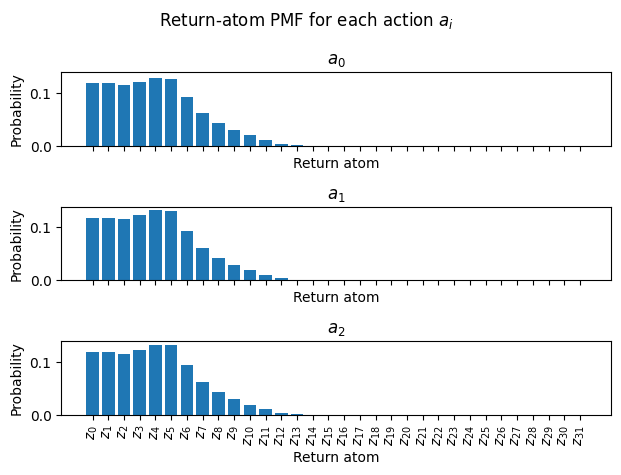

In [13]:
# Inspect the model again using the same observation used prior to training.
inspect_model_pmfs_for_observation(obs_inspect, config.model, atoms)

In [14]:
# obs_tmp=jnp.array([ 0.01716913, -0.02654778, -0.04510068, -0.00686742])
# inspect_model_pmfs_for_observation(obs_tmp, config.model, atoms)

In [15]:
# inspect_model_pmfs_for_observation(jnp.array([-0.01053775,  0.03950866, -0.03218421, -0.04678081]), config.model, atoms)

In [16]:
# Evaluate multiple times and preserve results.
# n_runs = 10
n_runs = 50
eval_metric_dict_runs = []
for r in range(n_runs):
    eval_metric_list = config.eval()
    eval_metric_dict = qnrl.tools.listofdict_to_dictoflist(eval_metric_list)
    eval_metric_dict_runs.append(eval_metric_dict)

# Report statistics across all runs.
for key in ('episode_step','episode_reward','episode_length','episode_time',):
    l = jnp.array([d[key][0] for d in eval_metric_dict_runs]) # Each key only has 1 entry.
    print(f"{key}: min: {jnp.min(l)}")
    print(f"{key}: max: {jnp.max(l)}")
    print(f"{key}: mean: {jnp.mean(l)}")
    print(f"{key}: std: {jnp.std(l)}")

  0%|          | 150/500000 [00:00<01:23, 5955.45step/s, episode_step=150, episode_reward=-151, episode_length=151, episode_time=0.0253]


episode_step: min: 147
episode_step: max: 199
episode_step: mean: 164.86
episode_step: std: 17.466550890201535
episode_reward: min: -200.0
episode_reward: max: -148.0
episode_reward: mean: -165.86
episode_reward: std: 17.466550890201535
episode_length: min: 148
episode_length: max: 200
episode_length: mean: 165.86
episode_length: std: 17.466550890201535
episode_time: min: 0.023903
episode_time: max: 0.039331
episode_time: mean: 0.027874500000000003
episode_time: std: 0.0032574686752139307
